In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [3]:
ts=np.load(r'D:\PhD Thesis Writing\Data\2025-09-24\20Mhz_Background_24hour_24_09_2025ts.npy')
xs=np.load(r'D:\PhD Thesis Writing\Data\2025-09-24\20Mhz_Background_24hour_24_09_2025xs.npy')

In [5]:
print(ts)

['16:45:46:861487' '16:45:47:885388' '16:45:48:909419' ...
 '16:38:28:991942' '16:38:30:003958' '16:38:31:031499']


In [7]:
from datetime import datetime

In [9]:
def timestamp_to_number(ts):
    dt = datetime.strptime(ts, "%H:%M:%S:%f")
    total_seconds = (
        dt.hour * 3600
        + dt.minute * 60
        + dt.second
        + dt.microsecond / 1e6
    )
    return total_seconds

In [11]:
numbers = [timestamp_to_number(ts) for ts in ts]

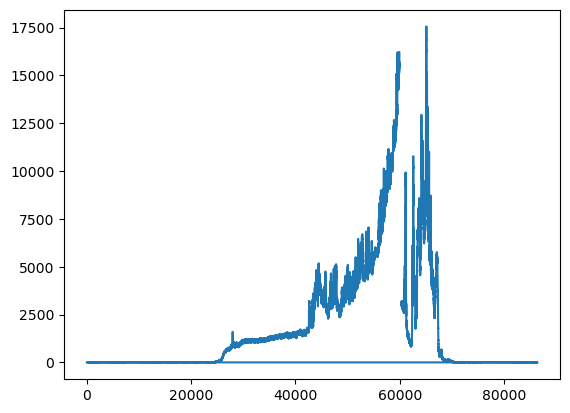

In [13]:
plt.plot(numbers,xs)

In [15]:
from datetime import datetime

def to_continuous_seconds(timestamps):
    # Parse into seconds since midnight
    parsed = []
    for ts in timestamps:
        dt = datetime.strptime(ts, "%H:%M:%S:%f")
        s = dt.hour * 3600 + dt.minute * 60 + dt.second + dt.microsecond / 1e6
        parsed.append(s)

    start = parsed[0]
    out = []
    for s in parsed:
        adj = s - start
        if adj < 0:  # wrapped past midnight
            adj += 24 * 3600
        out.append(adj)
    return out

In [17]:
x_seconds = to_continuous_seconds(ts)

In [29]:
%matplotlib inline

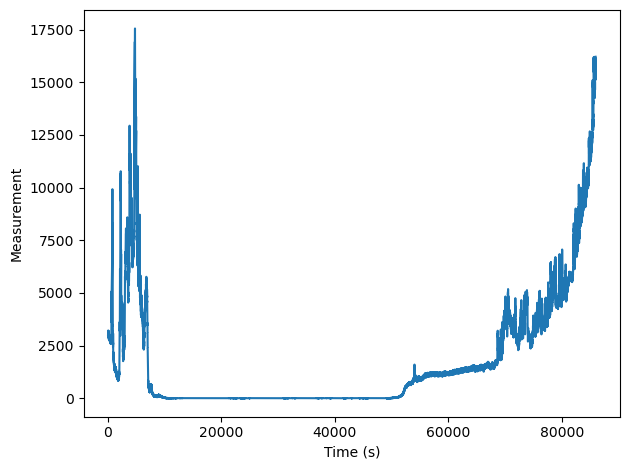

In [31]:
plt.plot(x_seconds, xs)  # hours since start (18:00 day 1)
plt.xlabel("Time (s)")
plt.ylabel("Measurement")
plt.tight_layout()
plt.show()

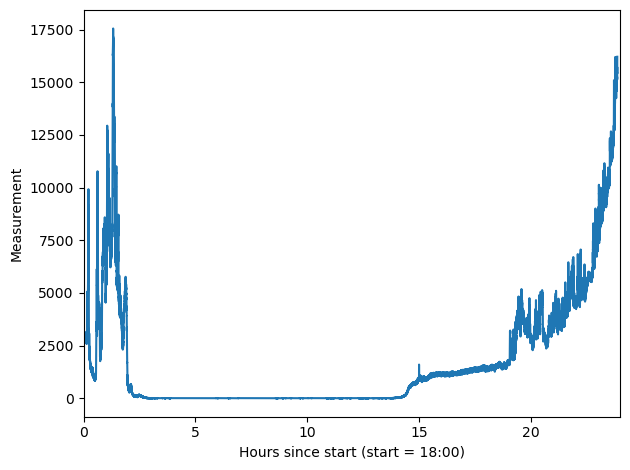

In [33]:
plt.plot([s/3600 for s in x_seconds], xs)  # hours since start (18:00 day 1)
plt.xlabel("Hours since start (start = 18:00)")
plt.ylabel("Measurement")
plt.xlim(0, 24)
plt.tight_layout()
plt.show()

In [35]:
xs_dark=xs[15000:45000]

In [37]:
ns_dark=[]
for i in range(len(xs_dark)):
    ns_dark.append(i)

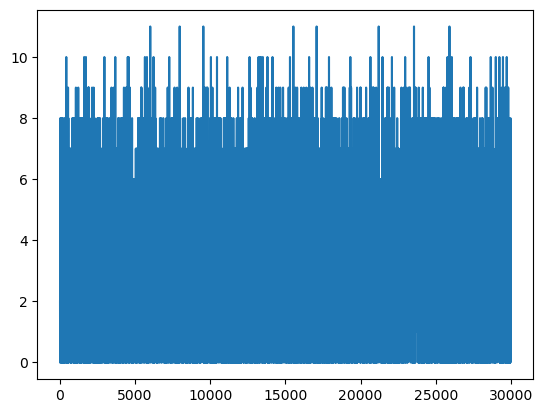

In [39]:
plt.plot(ns_dark,xs_dark)

In [41]:
ns=np.arange(0,len(ts))

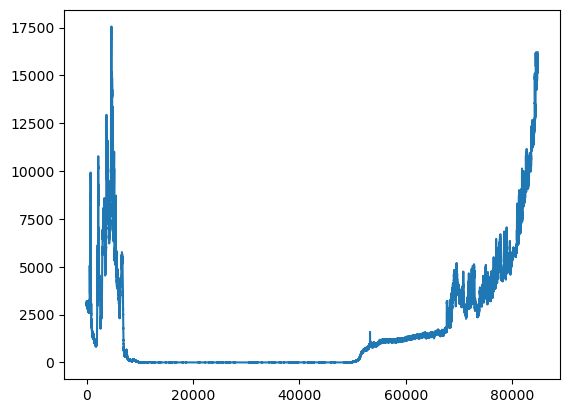

In [43]:
plt.plot(ns,xs)

In [45]:
receiver_bg_counts=xs

In [47]:
receiver_bg_seconds=x_seconds

In [49]:
np.save('receiver_bg_counts',receiver_bg_counts)
np.save('receiver_bg_seconds',receiver_bg_seconds)

In [51]:
numbers[0]

60346.861487

In [53]:
print(60346.861487/3600)

16.76301707972222


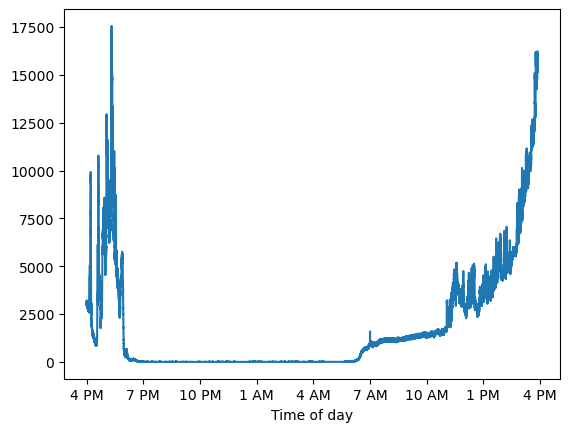

In [55]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import datetime as dt

# x_seconds = output from your to_continuous_seconds(timestamps)

fig, ax = plt.subplots()
ax.plot(x_seconds, xs)

timestamps=ts

# function: seconds since start -> clock label
def format_clock(x, pos):
    start_dt = dt.datetime.strptime(timestamps[0], "%H:%M:%S:%f")
    real_time = start_dt + dt.timedelta(seconds=x)
    try:
        return real_time.strftime("%-I %p")  # works on Linux/macOS
    except ValueError:
        return real_time.strftime("%#I %p")  # works on Windows

ax.xaxis.set_major_formatter(plt.FuncFormatter(format_clock))

# choose tick spacing: every 3 hours = 10800 s
ax.xaxis.set_major_locator(plt.MultipleLocator(3*3600))

plt.xlabel("Time of day")
plt.show()


In [57]:
san_ts=np.load(r'D:\PhD Thesis Writing\Data\2025-09-29\20Mhz_Background_Spectrum_fullmeasurement_29_09_25ts.npy')
san_xs=np.load(r'D:\PhD Thesis Writing\Data\2025-09-29\20Mhz_Background_Spectrum_fullmeasurement_29_09_25xs.npy')
san_ls=np.load(r'D:\PhD Thesis Writing\Data\2025-09-29\20Mhz_Background_Spectrum_fullmeasurement_29_09_25ls.npy')

In [59]:
san_ts=san_ts[:-9]
san_xs=san_xs[:-9]
san_ls=san_ls[:-9]

In [61]:
wavelength=1525
wavelength2=1610

In [63]:
wavelengths=[]
for i in range(851):
    wavelengths.append(wavelength+(i*0.1))

In [65]:
wavelengths2=[]
for i in range(len(wavelengths)):
    index=int(len(wavelengths)-(i+1))
    wavelengths2.append(wavelengths[index])

In [67]:
print(np.max(wavelengths))
print(np.min(wavelengths2))

1610.0
1525.0


In [130]:
wavelengths2

[1.61e-06,
 1.6099e-06,
 1.6098e-06,
 1.6097e-06,
 1.6096e-06,
 1.6095e-06,
 1.6094e-06,
 1.6093e-06,
 1.6092e-06,
 1.6091e-06,
 1.609e-06,
 1.6089e-06,
 1.6088e-06,
 1.6087e-06,
 1.6086e-06,
 1.6085e-06,
 1.6084e-06,
 1.6083e-06,
 1.6082000000000001e-06,
 1.6081000000000001e-06,
 1.608e-06,
 1.6079e-06,
 1.6078e-06,
 1.6077e-06,
 1.6076e-06,
 1.6075e-06,
 1.6074e-06,
 1.6073e-06,
 1.6072e-06,
 1.6071e-06,
 1.607e-06,
 1.6069e-06,
 1.6068e-06,
 1.6067e-06,
 1.6066e-06,
 1.6065e-06,
 1.6064e-06,
 1.6063e-06,
 1.6062e-06,
 1.6061e-06,
 1.606e-06,
 1.6059e-06,
 1.6058e-06,
 1.6057e-06,
 1.6056e-06,
 1.6055e-06,
 1.6054e-06,
 1.6053000000000001e-06,
 1.6052000000000001e-06,
 1.6051e-06,
 1.605e-06,
 1.6049e-06,
 1.6048e-06,
 1.6047e-06,
 1.6046e-06,
 1.6045e-06,
 1.6044e-06,
 1.6043e-06,
 1.6042e-06,
 1.6041e-06,
 1.604e-06,
 1.6039e-06,
 1.6038e-06,
 1.6037e-06,
 1.6036e-06,
 1.6035e-06,
 1.6034e-06,
 1.6033e-06,
 1.6032e-06,
 1.6031e-06,
 1.603e-06,
 1.6029e-06,
 1.6028e-06,
 1.6027e-06,

In [69]:
len(san_ls)/(len(wavelengths)+len(wavelengths2))

40.0

In [71]:
san_ls_fixed=[]
for i in range(int(len(san_ls)/(5*(len(wavelengths)+len(wavelengths2))))):
    for j in range(len(wavelengths)):
        san_ls_fixed.append(wavelengths[j])
        san_ls_fixed.append(wavelengths[j])
        san_ls_fixed.append(wavelengths[j])
        san_ls_fixed.append(wavelengths[j])
        san_ls_fixed.append(wavelengths[j])
    for j in range(len(wavelengths2)):
        san_ls_fixed.append(wavelengths2[j])
        san_ls_fixed.append(wavelengths2[j])
        san_ls_fixed.append(wavelengths2[j])
        san_ls_fixed.append(wavelengths2[j])
        san_ls_fixed.append(wavelengths2[j])

In [134]:
san_ls_fixed

[1.525e-06,
 1.5251e-06,
 1.5252e-06,
 1.5253e-06,
 1.5254e-06,
 1.5255e-06,
 1.5256e-06,
 1.5257e-06,
 1.5258e-06,
 1.5259e-06,
 1.526e-06,
 1.5261e-06,
 1.5262e-06,
 1.5263000000000001e-06,
 1.5264000000000001e-06,
 1.5265e-06,
 1.5266e-06,
 1.5267e-06,
 1.5268e-06,
 1.5269e-06,
 1.527e-06,
 1.5271e-06,
 1.5272e-06,
 1.5273e-06,
 1.5274e-06,
 1.5275e-06,
 1.5276e-06,
 1.5277e-06,
 1.5278e-06,
 1.5279e-06,
 1.528e-06,
 1.5281e-06,
 1.5282e-06,
 1.5283e-06,
 1.5284e-06,
 1.5285e-06,
 1.5286e-06,
 1.5287e-06,
 1.5288e-06,
 1.5289e-06,
 1.529e-06,
 1.5291000000000001e-06,
 1.5292000000000001e-06,
 1.5293e-06,
 1.5294e-06,
 1.5295e-06,
 1.5296e-06,
 1.5297e-06,
 1.5298e-06,
 1.5299e-06,
 1.53e-06,
 1.5301e-06,
 1.5302e-06,
 1.5303e-06,
 1.5304e-06,
 1.5305e-06,
 1.5306e-06,
 1.5307e-06,
 1.5308e-06,
 1.5309e-06,
 1.531e-06,
 1.5311e-06,
 1.5312e-06,
 1.5313e-06,
 1.5314e-06,
 1.5315e-06,
 1.5316e-06,
 1.5317e-06,
 1.5318e-06,
 1.5319e-06,
 1.5320000000000001e-06,
 1.5321e-06,
 1.5322e-06,

In [73]:
ns=[]
for i in range(len(san_ls)):
    ns.append(i)

In [75]:
len(san_ls)

68080

In [77]:
len(san_ls_fixed)

68080

In [79]:
san_ns=[]
for i in range(len(san_xs)):
    san_ns.append(i)

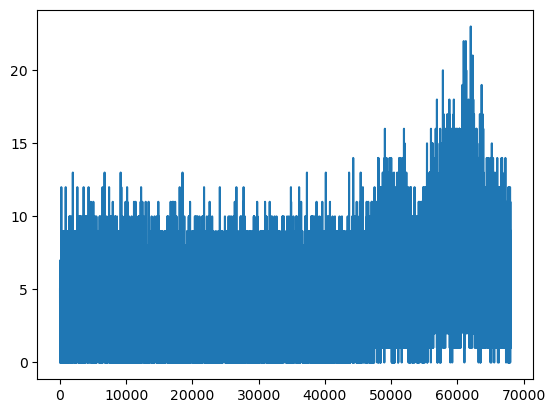

In [81]:
plt.plot(san_ns,san_xs)

In [83]:
print(san_ls[5])

1.5251e-06


In [85]:
ls_ref=wavelengths

In [87]:
np.max(ls_ref)

1610.0

In [89]:
np.min(ls_ref)

1525.0

In [91]:
san_xs_combined=np.zeros_like(ls_ref)

In [93]:
san_xs_combined=np.zeros_like(ls_ref)
for i in range(len(ls_ref)):
    for j in range(len(san_ls_fixed)):
        if san_ls_fixed[j] == ls_ref[i]:
            san_xs_combined[i]=san_xs_combined[i]+san_xs[j]

In [94]:
np.sum(san_xs)

301794

In [95]:
np.sum(san_xs_combined)

301794.0

In [96]:
from collections import Counter
counts = Counter(san_ls_fixed)

In [97]:
counts

Counter({1525.0: 80,
         1525.1: 80,
         1525.2: 80,
         1525.3: 80,
         1525.4: 80,
         1525.5: 80,
         1525.6: 80,
         1525.7: 80,
         1525.8: 80,
         1525.9: 80,
         1526.0: 80,
         1526.1: 80,
         1526.2: 80,
         1526.3: 80,
         1526.4: 80,
         1526.5: 80,
         1526.6: 80,
         1526.7: 80,
         1526.8: 80,
         1526.9: 80,
         1527.0: 80,
         1527.1: 80,
         1527.2: 80,
         1527.3: 80,
         1527.4: 80,
         1527.5: 80,
         1527.6: 80,
         1527.7: 80,
         1527.8: 80,
         1527.9: 80,
         1528.0: 80,
         1528.1: 80,
         1528.2: 80,
         1528.3: 80,
         1528.4: 80,
         1528.5: 80,
         1528.6: 80,
         1528.7: 80,
         1528.8: 80,
         1528.9: 80,
         1529.0: 80,
         1529.1: 80,
         1529.2: 80,
         1529.3: 80,
         1529.4: 80,
         1529.5: 80,
         1529.6: 80,
         1529

In [168]:
ls_ref[0]

1.525e-06

In [170]:
san_ls[851]

1.542e-06

In [98]:
%matplotlib inline

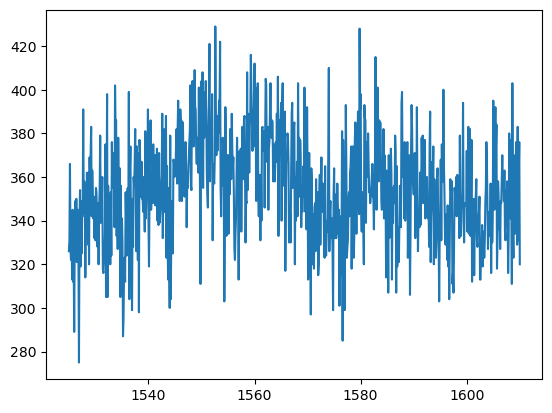

In [105]:
plt.plot(ls_ref,san_xs_combined)

In [107]:
eff=np.load('IDQubeEff.npy')

In [109]:
eff_norm=(eff-np.min(eff))/(np.max(eff)-np.min(eff))

In [111]:
eff_dec=eff/100
san_xs_com_norm=san_xs_combined/eff_dec

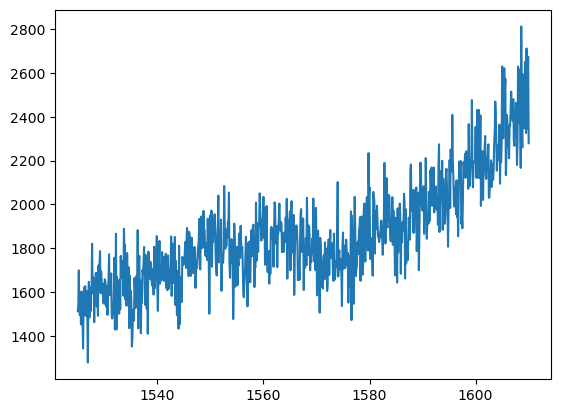

In [113]:
plt.plot(ls_ref,san_xs_com_norm)

In [115]:
%matplotlib inline

In [117]:
dc_measurement=san_xs[20000:40000]

In [119]:
darkcounts=3.32695652173913
vardc=0.007215377102753615

In [121]:
vardc

0.007215377102753615

In [123]:
darkcounts

3.32695652173913

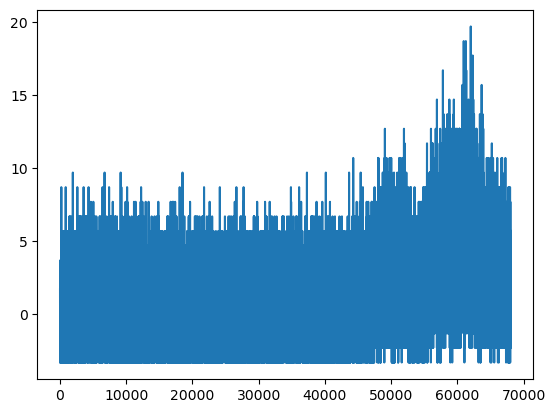

In [125]:
plt.plot(san_ns,san_xs-darkcounts)

In [127]:
san_xs_undark=san_xs-darkcounts

In [129]:
np.mean(san_xs_undark[20000:40000])

0.24759347826086978

In [131]:
len(san_xs_undark)/5

13616.0

In [133]:
san_xs_undark_ave=[]
san_ts_undark_ave=[]
san_ls_undark_ave=[]
s_xs_ud_var=[]
s_xs_ud_std=[]
for i in range(int(len(san_xs_undark)/5)):
    i1=5*i
    i2=(5*i)+5
    xs_av=np.sum(san_xs_undark[i1:i2])
    xs_var=(np.sum(san_xs[i1:i2])+(5*vardc))
    ts_av=san_ts[(i*5)+2]
    ls_av=np.mean(san_ls_fixed[i1:i2])
    san_xs_undark_ave.append(xs_av)
    san_ts_undark_ave.append(ts_av)
    san_ls_undark_ave.append(ls_av)
    s_xs_ud_var.append(xs_var)
    s_xs_ud_std.append(np.sqrt(xs_var))

In [135]:
san_ns_ave=[]
for i in range(len(san_xs_undark_ave)):
    san_ns_ave.append(i)

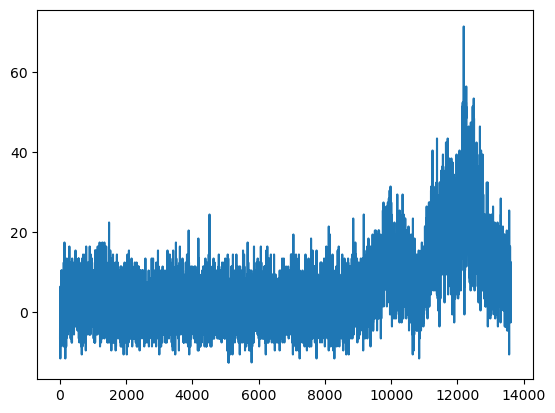

In [137]:
plt.plot(san_ns_ave,san_xs_undark_ave)

In [139]:
%matplotlib inline

In [222]:
s_xs_ud_var

[9.0008936375,
 13.0008936375,
 14.0008936375,
 7.0008936375,
 11.0008936375,
 9.0008936375,
 13.0008936375,
 10.0008936375,
 7.0008936375,
 8.0008936375,
 4.0008936375,
 10.0008936375,
 18.0008936375,
 10.0008936375,
 17.0008936375,
 12.0008936375,
 17.0008936375,
 19.0008936375,
 14.0008936375,
 14.0008936375,
 15.0008936375,
 8.0008936375,
 12.0008936375,
 14.0008936375,
 15.0008936375,
 10.0008936375,
 11.0008936375,
 13.0008936375,
 11.0008936375,
 13.0008936375,
 8.0008936375,
 15.0008936375,
 16.0008936375,
 11.0008936375,
 18.0008936375,
 14.0008936375,
 10.0008936375,
 16.0008936375,
 14.0008936375,
 21.0008936375,
 22.0008936375,
 14.0008936375,
 13.0008936375,
 11.0008936375,
 12.0008936375,
 6.0008936375,
 12.0008936375,
 6.0008936375,
 16.0008936375,
 9.0008936375,
 6.0008936375,
 11.0008936375,
 18.0008936375,
 9.0008936375,
 16.0008936375,
 22.0008936375,
 11.0008936375,
 8.0008936375,
 10.0008936375,
 13.0008936375,
 15.0008936375,
 10.0008936375,
 15.0008936375,
 18.00

In [224]:
s_xs_ud_std

[3.0001489358863505,
 3.605675198558517,
 3.7417768022023976,
 2.645920187288347,
 3.316759508541432,
 3.0001489358863505,
 3.605675198558517,
 3.1624189535069513,
 2.645920187288347,
 2.828585094618863,
 2.0002233968984564,
 3.1624189535069513,
 4.2427460020015335,
 3.1624189535069513,
 4.123213993658345,
 3.4642305981992596,
 4.123213993658345,
 4.35900144958682,
 3.7417768022023976,
 3.7417768022023976,
 3.8730987125943486,
 2.828585094618863,
 3.4642305981992596,
 3.7417768022023976,
 3.8730987125943486,
 3.1624189535069513,
 3.316759508541432,
 3.605675198558517,
 3.316759508541432,
 3.605675198558517,
 2.828585094618863,
 3.8730987125943486,
 4.000111703127801,
 3.316759508541432,
 4.2427460020015335,
 3.7417768022023976,
 3.1624189535069513,
 4.000111703127801,
 3.7417768022023976,
 4.582673197763506,
 4.690511020933647,
 3.7417768022023976,
 3.605675198558517,
 3.316759508541432,
 3.4642305981992596,
 2.44967214898239,
 3.4642305981992596,
 2.44967214898239,
 4.000111703127801,

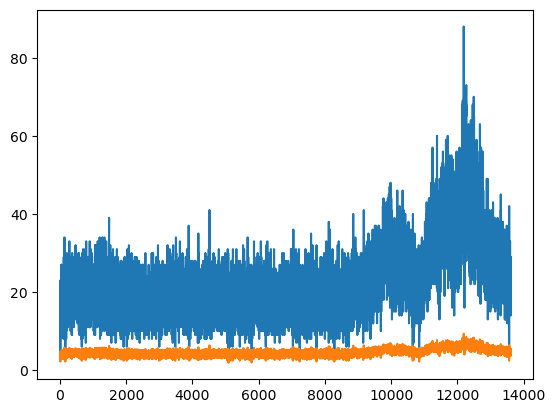

In [141]:
plt.plot(san_ns_ave,s_xs_ud_var)
plt.plot(san_ns_ave,s_xs_ud_std)

<ErrorbarContainer object of 3 artists>

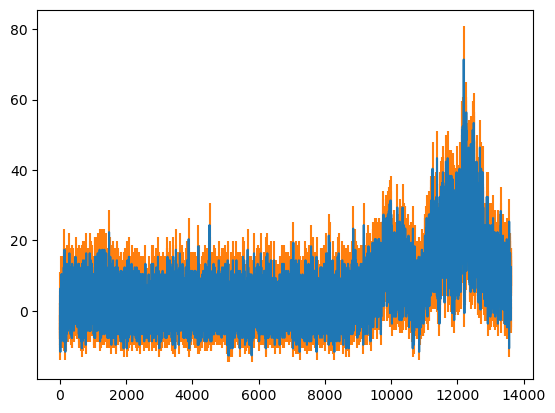

In [143]:
plt.errorbar(san_ns_ave,san_xs_undark_ave,yerr=s_xs_ud_std,ecolor='tab:orange')

In [145]:
san_xs_undark_ave_combined=np.zeros_like(ls_ref)
san_xs_undark_ave_combined_var=np.zeros_like(ls_ref)
for i in range(len(ls_ref)):
    for j in range(len(san_ls_undark_ave)):
        if san_ls_undark_ave[j] == ls_ref[i]:
            san_xs_undark_ave_combined[i]=san_xs_undark_ave_combined[i]+san_xs_undark_ave[j]
            san_xs_undark_ave_combined_var[i]=san_xs_undark_ave_combined_var[i]+s_xs_ud_var[j]
san_xs_undark_ave_combined_std=np.sqrt(san_xs_undark_ave_combined_var)

In [146]:
len(san_ns_ave)/len(ls_ref)

16.0

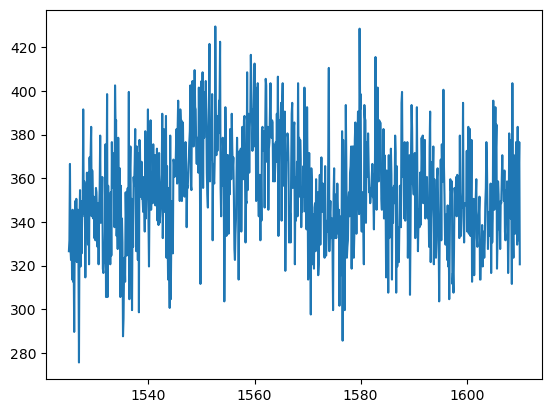

In [149]:
plt.plot(ls_ref,san_xs_undark_ave_combined_var)

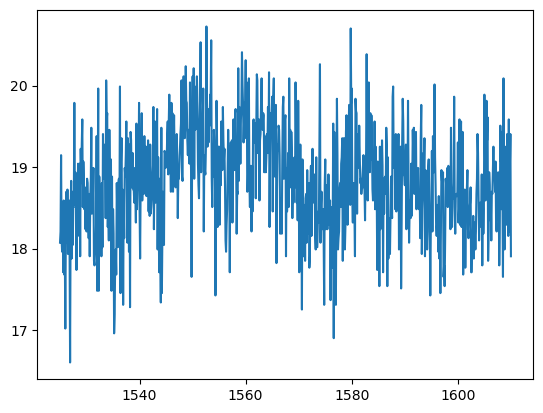

In [151]:
plt.plot(ls_ref,san_xs_undark_ave_combined_std)

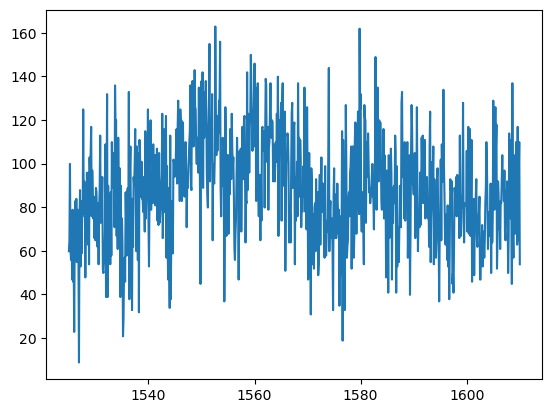

In [153]:
plt.plot(ls_ref,san_xs_undark_ave_combined)

<ErrorbarContainer object of 3 artists>

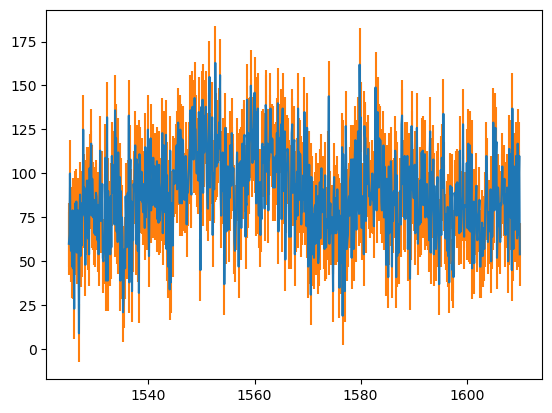

In [155]:
plt.errorbar(ls_ref,san_xs_undark_ave_combined,yerr=san_xs_undark_ave_combined_std,ecolor='tab:orange')

In [157]:
eff_dec=eff/100

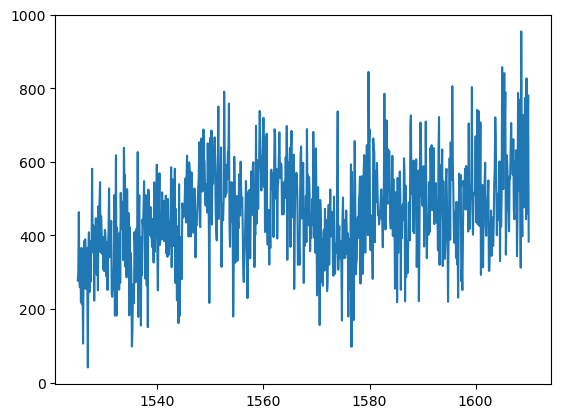

In [159]:
plt.plot(ls_ref,(san_xs_undark_ave_combined)/eff_dec)

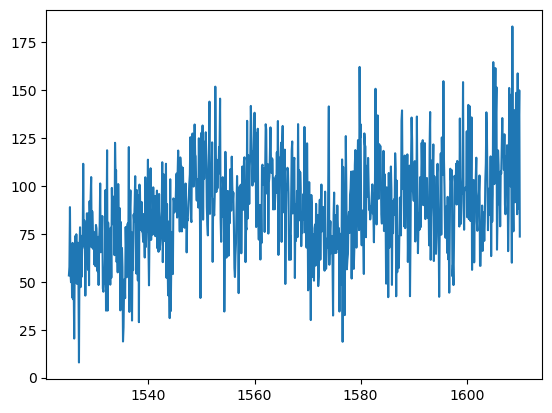

In [161]:
plt.plot(ls_ref,(san_xs_undark_ave_combined*np.mean(eff_dec))/eff_dec)

In [163]:
san_xs_effcor=(san_xs_undark_ave_combined*np.mean(eff_dec))/eff_dec
san_xs_effcor_var=(san_xs_undark_ave_combined_var*(np.mean(eff_dec)**2))/(eff_dec**2)
san_xs_effcor_std=(san_xs_undark_ave_combined_std*np.mean(eff_dec))/eff_dec

In [165]:
(np.mean(eff_dec)*10)/np.sum(eff_dec[840:849])

1.505519796378628

In [167]:
(np.mean(eff_dec))/eff_dec[840]

1.3470391074994434

In [169]:
(np.mean(eff_dec))/eff_dec[844]

1.354967816740767

In [171]:
((1.354967816740767*10)*16)**2

47000.007280722966

In [173]:
0.0001787275*47000.007280722966

8.400193801265415

In [175]:
np.sqrt(0.0001787275*47000.007280722966)

2.8983087829397016

<ErrorbarContainer object of 3 artists>

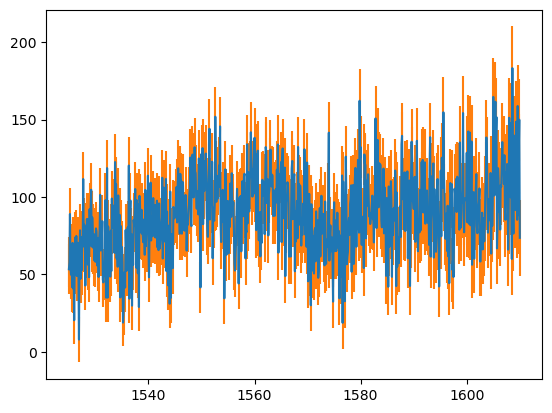

In [177]:
plt.errorbar(ls_ref,san_xs_effcor,yerr=san_xs_effcor_std,ecolor='tab:orange')

In [179]:
np.save('rec_bg_sum_ls',ls_ref)
np.save('rec_bg_sum_xs',san_xs_effcor)
np.save('rec_bg_sum_std',san_xs_effcor_std)

In [181]:
ls_ref_bin=[]
san_xs_bin=[]
san_xs_bin_var=[]
for i in range(int(len(san_xs_effcor)/10)):
    i1=10*i
    i2=(10*i)+10
    xs_sum=np.sum(san_xs_effcor[i1:i2])
    xs_var=np.sum(san_xs_effcor_var[i1:i2])
    ls_av=np.mean(ls_ref[i1:i2])
    san_xs_bin.append(xs_sum)
    ls_ref_bin.append(ls_av)
    san_xs_bin_var.append(xs_var)
san_xs_bin_std=np.sqrt(san_xs_bin_var)

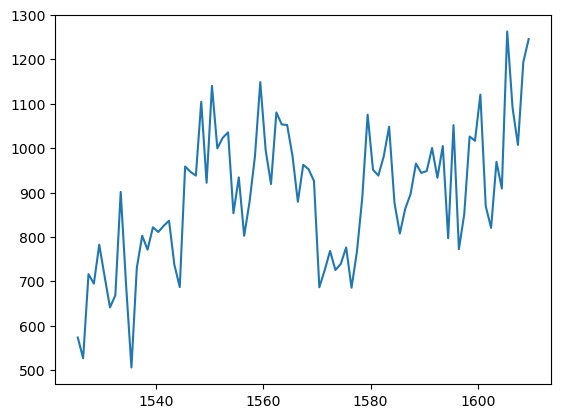

In [183]:
plt.plot(ls_ref_bin,san_xs_bin)

In [185]:
np.sum(san_xs_undark)

75294.80000000002

In [959]:
np.sum(san_xs_undark_ave)

75294.80000000002

In [961]:
np.sum(san_xs_effcor)

75983.70538789938

In [963]:
np.sum(san_xs_bin)

75910.08603547885

In [187]:
san_xs_bin_std

array([51.29642507, 50.94297892, 52.63370782, 52.51625808, 53.32400602,
       52.78886908, 52.26700042, 52.57627765, 54.61149729, 52.93085369,
       51.3860781 , 53.4016986 , 54.08766773, 53.90150716, 54.40257198,
       54.3834933 , 54.57674011, 54.75190077, 53.99310923, 53.65496676,
       56.01330364, 56.00003804, 56.01793035, 57.45124968, 56.05537711,
       57.9368417 , 56.90338716, 57.20211868, 57.40843843, 56.01344272,
       56.79129426, 55.80158966, 56.54783607, 57.50004706, 58.97300214,
       57.85023179, 57.33202447, 58.76398107, 58.66424513, 58.77975199,
       58.33440082, 57.60153715, 58.41827569, 58.46965823, 58.39847476,
       56.53143771, 57.02176723, 57.54726408, 57.33583066, 57.60978778,
       58.08351552, 57.4652656 , 58.31544557, 59.50745046, 61.22027576,
       60.37157706, 60.43106362, 60.99676533, 61.81527517, 60.71256889,
       60.49169887, 61.36904459, 62.12934961, 63.24482097, 63.669449  ,
       64.35601438, 65.51468388, 65.71359812, 67.11751237, 66.13

<ErrorbarContainer object of 3 artists>

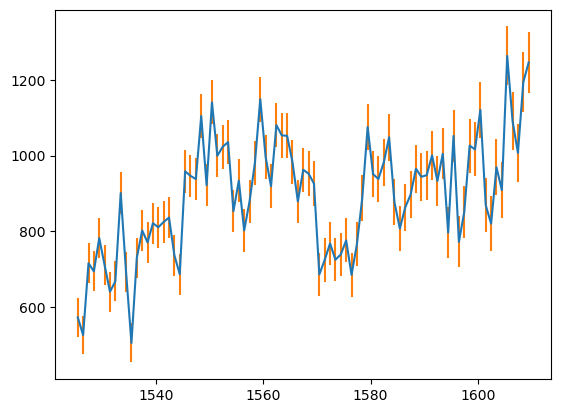

In [189]:
plt.errorbar(ls_ref_bin,san_xs_bin,yerr=san_xs_bin_std,ecolor='tab:orange')

In [191]:
ls_ref_bin

[1525.45,
 1526.45,
 1527.45,
 1528.45,
 1529.45,
 1530.45,
 1531.45,
 1532.45,
 1533.45,
 1534.45,
 1535.45,
 1536.45,
 1537.45,
 1538.45,
 1539.45,
 1540.45,
 1541.45,
 1542.45,
 1543.45,
 1544.45,
 1545.45,
 1546.45,
 1547.45,
 1548.45,
 1549.45,
 1550.45,
 1551.45,
 1552.45,
 1553.45,
 1554.45,
 1555.45,
 1556.45,
 1557.45,
 1558.45,
 1559.45,
 1560.45,
 1561.45,
 1562.45,
 1563.45,
 1564.45,
 1565.45,
 1566.45,
 1567.45,
 1568.45,
 1569.45,
 1570.45,
 1571.45,
 1572.45,
 1573.45,
 1574.45,
 1575.45,
 1576.45,
 1577.45,
 1578.45,
 1579.45,
 1580.45,
 1581.45,
 1582.45,
 1583.45,
 1584.45,
 1585.45,
 1586.45,
 1587.45,
 1588.45,
 1589.45,
 1590.45,
 1591.45,
 1592.45,
 1593.45,
 1594.45,
 1595.45,
 1596.45,
 1597.45,
 1598.45,
 1599.45,
 1600.45,
 1601.45,
 1602.45,
 1603.45,
 1604.45,
 1605.45,
 1606.45,
 1607.45,
 1608.45,
 1609.45]

In [193]:
np.save('rec_bg_sum_binned_ls',ls_ref_bin)
np.save('rec_bg_sum_binned_xs',san_xs_bin)
np.save('rec_bg_sum_binned_std',san_xs_bin_std)

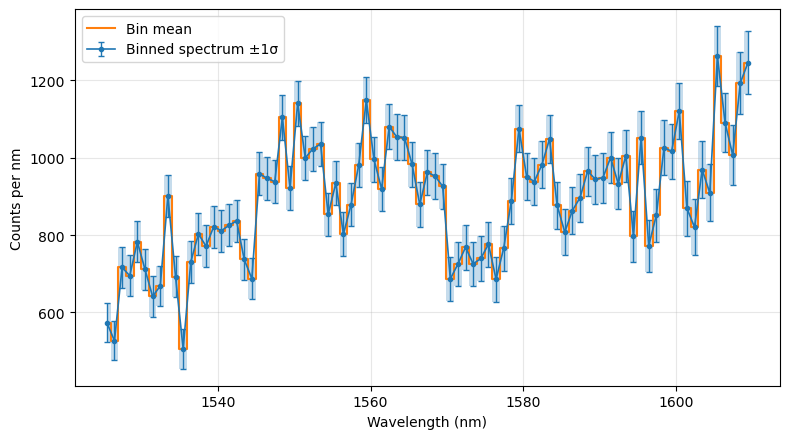

In [195]:
import numpy as np
import matplotlib.pyplot as plt

# Your data
lam = ls_ref_bin                      # wavelength array (nm), shape (N,)
counts = san_xs_bin                   # corrected counts (or rate), shape (N,)
sigma = san_xs_bin_std                   # 1σ per point (sqrt(variance)), shape (N,)

fig, ax = plt.subplots(figsize=(8,4.5))

ax.errorbar(lam, counts, yerr=sigma,
            fmt='o-', ms=3, lw=1.2, capsize=2, elinewidth=1,
            label="Binned spectrum ±1σ")
# lam are bin centers, width = 1.0 nm
ax.step(lam, counts, where='mid', lw=1.5, label="Bin mean")
ax.fill_between(lam, counts - sigma, counts + sigma, step='mid', alpha=0.25)

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Counts per nm")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [292]:
san_xs_undark_ave
san_ts_undark_ave
san_ls_undark_ave
s_xs_ud_var
s_xs_ud_std
san_ns_ave

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39,
 40,
 41,
 42,
 43,
 44,
 45,
 46,
 47,
 48,
 49,
 50,
 51,
 52,
 53,
 54,
 55,
 56,
 57,
 58,
 59,
 60,
 61,
 62,
 63,
 64,
 65,
 66,
 67,
 68,
 69,
 70,
 71,
 72,
 73,
 74,
 75,
 76,
 77,
 78,
 79,
 80,
 81,
 82,
 83,
 84,
 85,
 86,
 87,
 88,
 89,
 90,
 91,
 92,
 93,
 94,
 95,
 96,
 97,
 98,
 99,
 100,
 101,
 102,
 103,
 104,
 105,
 106,
 107,
 108,
 109,
 110,
 111,
 112,
 113,
 114,
 115,
 116,
 117,
 118,
 119,
 120,
 121,
 122,
 123,
 124,
 125,
 126,
 127,
 128,
 129,
 130,
 131,
 132,
 133,
 134,
 135,
 136,
 137,
 138,
 139,
 140,
 141,
 142,
 143,
 144,
 145,
 146,
 147,
 148,
 149,
 150,
 151,
 152,
 153,
 154,
 155,
 156,
 157,
 158,
 159,
 160,
 161,
 162,
 163,
 164,
 165,
 166,
 167,
 168,
 169,
 170,
 171,
 172,
 173,
 174,
 175,
 176,
 177,
 178,
 179,
 180,
 181,
 182,
 183,
 184,


In [197]:
san_xs_per_ls=[]
for i in range(len(ls_ref)):
    xpl=[]
    tpl=[]
    xplvar=[]
    xplstd=[]
    for j in range(len(san_ls_undark_ave)):
        if san_ls_undark_ave[j]==ls_ref[i]:
            xpl.append((san_xs_undark_ave[j]*np.mean(eff_dec))/eff_dec[i])
            tpl.append(san_ts_undark_ave[j])
            xplvar.append(s_xs_ud_var[j])
            xplstd.append(s_xs_ud_std[j])
    san_xs_per_ls.append([ls_ref[i],xpl,tpl,xplvar,xplstd])

In [198]:
san_xs_per_ls[9][1]

[-5.918021905400872,
 -0.5662065518928739,
 5.677578027199791,
 -7.701960356570206,
 6.569547252784457,
 3.8936395760304583,
 6.569547252784457,
 -3.242114228646873,
 3.001670350445792,
 7.461516478369123,
 -5.026052679816206,
 4.785608801615124,
 10.137424155123123,
 7.461516478369123,
 9.245454929538456,
 8.353485703953789]

In [201]:
san_xs_per_ls[0][2]

['15:54:37:829372',
 '19:01:22:288021',
 '19:01:28:842576',
 '22:08:44:023645',
 '22:08:50:610517',
 '01:16:06:639577',
 '01:16:13:242552',
 '04:23:27:863170',
 '04:23:34:465952',
 '07:30:49:346846',
 '07:30:55:950913',
 '10:38:12:484748',
 '10:38:19:056766',
 '13:45:35:862418',
 '13:45:42:482483',
 '16:53:00:374328']

In [203]:
tempns=np.linspace(1,16,16)

In [205]:
tempns

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13.,
       14., 15., 16.])

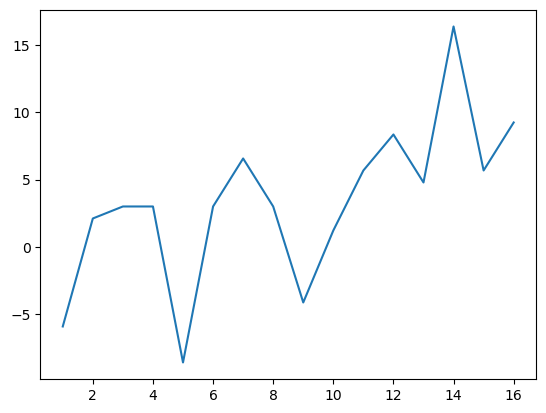

In [207]:
plt.plot(tempns,san_xs_per_ls[0][1])

In [209]:
san_xs_per_ls[0][4]

[3.167976781088171,
 4.363035283551323,
 4.4761676560997765,
 4.4761676560997765,
 2.6525604395590627,
 4.4761676560997765,
 4.902660184584872,
 4.4761676560997765,
 3.4693049571223584,
 4.246890260592304,
 4.799591324843582,
 5.102555916941408,
 4.694259993387005,
 5.919128051116462,
 4.799591324843582,
 5.199622763769865]

In [211]:
xs_cml=[]
ts_mid=[]
for i in range(len(san_xs_per_ls[0][1])):
    xs_sum=0
    for j in range(10):
        print(san_xs_per_ls[j][1][i])
        xs_sum=xs_sum+san_xs_per_ls[j][1][i]
    xs_cml.append(xs_sum)
    ts_mid.append(san_xs_per_ls[4][2][i])

-5.911886087422629
-1.456831765032408
0.3254999175817238
-4.131224981865748
-1.4573354792582005
-6.806851271929324
-2.3493322294556562
-4.133130190692987
-7.701072270414623
-5.918021905400872
2.1075137821480423
2.107756596217104
0.3254999175817238
0.32553742821456316
1.2170301608698824
3.0002863806795563
1.217310759156893
3.0009782060003514
1.217591486863139
-0.5662065518928739
2.9985582121003396
2.107756596217104
7.4554981122289785
2.1082423922466877
-1.4573354792582005
5.674960285936524
4.783953747769443
4.784505305173686
-4.133606767503517
5.677578027199791
2.9985582121003396
-0.5656846747200299
11.911746983883514
0.32553742821456316
4.782851014373993
-1.4575034614153897
2.1089715063100303
4.784505305173686
-1.4580076403201894
-7.701960356570206
-8.58501937727952
-1.456831765032408
3.8904990149053518
1.2168899102306252
-1.4573354792582005
0.32561247542258864
-3.2409929766087937
2.1092146564136836
8.352522492685347
6.569547252784457
2.9985582121003396
-0.5656846747200299
3.8904990149

In [213]:
san_xs_per_ls[0][2]

['15:54:37:829372',
 '19:01:22:288021',
 '19:01:28:842576',
 '22:08:44:023645',
 '22:08:50:610517',
 '01:16:06:639577',
 '01:16:13:242552',
 '04:23:27:863170',
 '04:23:34:465952',
 '07:30:49:346846',
 '07:30:55:950913',
 '10:38:12:484748',
 '10:38:19:056766',
 '13:45:35:862418',
 '13:45:42:482483',
 '16:53:00:374328']

In [215]:
xs_cml

[-39.54018626389072,
 13.95329816583838,
 30.000110432110837,
 15.72901431703031,
 7.724106204263131,
 14.848351369729869,
 5.036897957434931,
 14.841259067280635,
 5.044807775930613,
 11.279447604415864,
 25.533482304121275,
 66.55584087362789,
 95.97591922458086,
 129.84844656935718,
 111.12305781501409,
 65.6577066052415]

In [217]:
def cummaltive_counts(index):
    xs_cml=[]
    ts_mid=[]
    for i in range(len(san_xs_per_ls[0][1])):
        xs_sum=0
        for j in range(10):
            xs_sum=xs_sum+san_xs_per_ls[j+(10*index)][1][i]
        xs_cml.append(xs_sum)
        ts_mid.append(san_xs_per_ls[4+(10*index)][2][i])
    return xs_cml,ts_mid

In [219]:
cctest1,cctest2=cummaltive_counts(0)

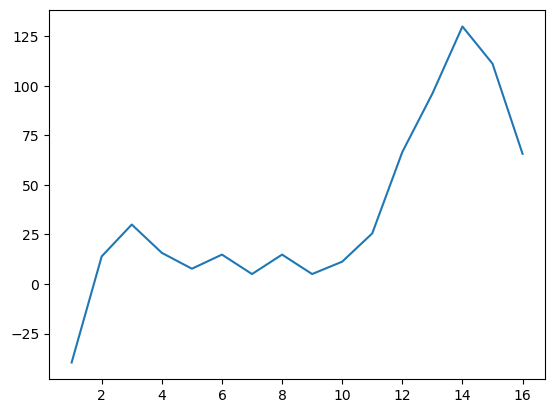

In [221]:
plt.plot(tempns,cctest1)

In [223]:
np.sum(cctest1)

573.6115600220867

In [225]:
bin_counts=[]
bin_timestamps=[]
for i in range(85):
    ct1,ct2=cummaltive_counts(i)
    bin_counts.append(ct1)
    bin_timestamps.append(ct2)

In [227]:
bin_counts[0]

[-39.54018626389072,
 13.95329816583838,
 30.000110432110837,
 15.72901431703031,
 7.724106204263131,
 14.848351369729869,
 5.036897957434931,
 14.841259067280635,
 5.044807775930613,
 11.279447604415864,
 25.533482304121275,
 66.55584087362789,
 95.97591922458086,
 129.84844656935718,
 111.12305781501409,
 65.6577066052415]

In [229]:
#ls_ref_bin
#bin_counts
bin_timestamps

[['15:55:04:087860',
  '19:00:55:810268',
  '19:01:55:288217',
  '22:08:17:578059',
  '22:09:17:056394',
  '01:15:40:258703',
  '01:16:39:689542',
  '04:23:01:482365',
  '04:24:00:880464',
  '07:30:22:982546',
  '07:31:22:412372',
  '10:37:46:040382',
  '10:38:45:502504',
  '13:45:09:432514',
  '13:46:08:927421',
  '16:52:34:007446'],
 ['15:56:09:783201',
  '18:59:49:791360',
  '19:03:01:322625',
  '22:07:11:447573',
  '22:10:23:187306',
  '01:14:34:238398',
  '01:17:45:658124',
  '04:21:55:350942',
  '04:25:07:009911',
  '07:29:16:948009',
  '07:32:28:445192',
  '10:36:39:957574',
  '10:39:51:569150',
  '13:44:03:350273',
  '13:47:14:994919',
  '16:51:27:876529'],
 ['15:57:15:596184',
  '18:58:43:708370',
  '19:04:07:341306',
  '22:06:05:332688',
  '22:11:29:364472',
  '01:13:28:155751',
  '01:18:51:676665',
  '04:20:49:332538',
  '04:26:13:092685',
  '07:28:10:784384',
  '07:33:34:415517',
  '10:35:33:939585',
  '10:40:57:555231',
  '13:42:57:251576',
  '13:48:21:156271',
  '16:50:21

In [252]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter
from matplotlib.colors import TwoSlopeNorm
# ---------- helpers ----------
def _parse_hhmmss_us(s):
    return datetime.strptime(s, "%H:%M:%S:%f")

def _unwrap_time_seconds(time_strs):
    """Return (t_rel, t0_day_sec, t_abs), where:
       t_rel: seconds since first timestamp (monotonic, spans midnight)
       t0_day_sec: first timestamp’s seconds since its midnight (for labeling)
       t_abs: absolute seconds since day0 midnight (monotonic)"""
    sec = np.array([t.hour*3600 + t.minute*60 + t.second + t.microsecond/1e6
                    for t in map(_parse_hhmmss_us, time_strs)], dtype=float)
    # unwrap across midnight
    day_off = 0.0
    t_abs = np.empty_like(sec)
    t_abs[0] = sec[0]
    for i in range(1, len(sec)):
        if sec[i] < sec[i-1] - 1e-9:
            day_off += 24*3600
        t_abs[i] = sec[i] + day_off
    t_rel = t_abs - t_abs[0]
    t0_day_sec = sec[0]  # seconds since its midnight (for clock labels)
    return t_rel, t0_day_sec, t_abs

def _as_seq_of_floats(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        if len(x) == 1 and isinstance(x[0], (list, tuple, np.ndarray)):
            return np.asarray(x[0], dtype=float)
        return np.asarray(x, dtype=float)
    raise TypeError(f"Counts entry has unexpected type: {type(x)}")

def _as_seq_of_strs(x):
    if isinstance(x, str):
        return [x]
    if isinstance(x, (list, tuple, np.ndarray)):
        if len(x) == 1 and isinstance(x[0], (list, tuple, np.ndarray)):
            return [str(s) for s in x[0]]
        return [str(s) for s in x]
    raise TypeError(f"Timestamps entry has unexpected type: {type(x)}")

# ---------- build matrices ----------
def build_time_wavelength_matrix(wavelengths_m, counts_nested, timestr_nested):
    lam_nm = np.array(wavelengths_m, dtype=float) * 1e9
    order = np.argsort(lam_nm)
    lam_nm = lam_nm[order]

    counts_list = [_as_seq_of_floats(counts_nested[i]) for i in order]
    times_list  = [_as_seq_of_strs(timestr_nested[i])  for i in order]
    for k,(ck,tk) in enumerate(zip(counts_list, times_list)):
        if len(ck) != len(tk):
            raise ValueError(f"Wavelength {k}: counts len {len(ck)} != time len {len(tk)}")

    # unwrap using the first wavelength to set the clock anchor
    t_rel0, t0_day_sec, t_abs0 = _unwrap_time_seconds(times_list[0])

    # assume all wavelengths share the same timestamps; still handle small differences robustly
    t_rel_all = []
    for ts in times_list:
        t_rel, _, _ = _unwrap_time_seconds(ts)
        t_rel_all.append(t_rel)

    # union of all times (native)
    all_t = np.unique(np.concatenate(t_rel_all))
    Nt, Nw = all_t.size, lam_nm.size

    # fill sparse matrix at native times
    M_native = np.full((Nw, Nt), np.nan)
    for k in range(Nw):
        tk = t_rel_all[k]
        ck = counts_list[k]
        idx = np.searchsorted(all_t, tk)
        good = (idx >= 0) & (idx < Nt) & (np.isclose(all_t[idx], tk, atol=1e-6))
        M_native[k, idx[good]] = ck[good]

    return lam_nm, all_t, M_native, t0_day_sec
# ---------- helpers ----------
def _parse_hhmmss_us(s):
    return datetime.strptime(s, "%H:%M:%S:%f")

def _unwrap_time_seconds(time_strs):
    """Return (t_rel, t0_day_sec, t_abs), where:
       t_rel: seconds since first timestamp (monotonic, spans midnight)
       t0_day_sec: first timestamp’s seconds since its midnight (for labeling)
       t_abs: absolute seconds since day0 midnight (monotonic)"""
    sec = np.array([t.hour*3600 + t.minute*60 + t.second + t.microsecond/1e6
                    for t in map(_parse_hhmmss_us, time_strs)], dtype=float)
    # unwrap across midnight
    day_off = 0.0
    t_abs = np.empty_like(sec)
    t_abs[0] = sec[0]
    for i in range(1, len(sec)):
        if sec[i] < sec[i-1] - 1e-9:
            day_off += 24*3600
        t_abs[i] = sec[i] + day_off
    t_rel = t_abs - t_abs[0]
    t0_day_sec = sec[0]  # seconds since its midnight (for clock labels)
    return t_rel, t0_day_sec, t_abs

def _as_seq_of_floats(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        if len(x) == 1 and isinstance(x[0], (list, tuple, np.ndarray)):
            return np.asarray(x[0], dtype=float)
        return np.asarray(x, dtype=float)
    raise TypeError(f"Counts entry has unexpected type: {type(x)}")

def _as_seq_of_strs(x):
    if isinstance(x, str):
        return [x]
    if isinstance(x, (list, tuple, np.ndarray)):
        if len(x) == 1 and isinstance(x[0], (list, tuple, np.ndarray)):
            return [str(s) for s in x[0]]
        return [str(s) for s in x]
    raise TypeError(f"Timestamps entry has unexpected type: {type(x)}")

# ---------- build matrices ----------
def build_time_wavelength_matrix(wavelengths_m, counts_nested, timestr_nested):
    lam_nm = np.array(wavelengths_m, dtype=float) * 1e9
    order = np.argsort(lam_nm)
    lam_nm = lam_nm[order]

    counts_list = [_as_seq_of_floats(counts_nested[i]) for i in order]
    times_list  = [_as_seq_of_strs(timestr_nested[i])  for i in order]
    for k,(ck,tk) in enumerate(zip(counts_list, times_list)):
        if len(ck) != len(tk):
            raise ValueError(f"Wavelength {k}: counts len {len(ck)} != time len {len(tk)}")

    # unwrap using the first wavelength to set the clock anchor
    t_rel0, t0_day_sec, t_abs0 = _unwrap_time_seconds(times_list[0])

    # assume all wavelengths share the same timestamps; still handle small differences robustly
    t_rel_all = []
    for ts in times_list:
        t_rel, _, _ = _unwrap_time_seconds(ts)
        t_rel_all.append(t_rel)

    # union of all times (native)
    all_t = np.unique(np.concatenate(t_rel_all))
    Nt, Nw = all_t.size, lam_nm.size

    # fill sparse matrix at native times
    M_native = np.full((Nw, Nt), np.nan)
    for k in range(Nw):
        tk = t_rel_all[k]
        ck = counts_list[k]
        idx = np.searchsorted(all_t, tk)
        good = (idx >= 0) & (idx < Nt) & (np.isclose(all_t[idx], tk, atol=1e-6))
        M_native[k, idx[good]] = ck[good]

    return lam_nm, all_t, M_native, t0_day_sec
    
def plot_time_wavelength_map_custom(lam_nm, t_rel_s, M, t0_day_sec,
                                    major_h=6, minor_h=2,
                                    pct_low=1, pct_high=99,
                                    cmap='coolwarm',
                                    t_native_s=None):
    """Gradient map with custom ticks and robust colour scale."""
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.ticker import MultipleLocator, FuncFormatter
    from matplotlib.colors import TwoSlopeNorm

    # ----- cell edges -----
    dt = np.median(np.diff(t_rel_s)) if len(t_rel_s) > 1 else 60.0
    t_edges = np.concatenate(([t_rel_s[0]-dt/2],
                              (t_rel_s[:-1]+t_rel_s[1:])/2,
                              [t_rel_s[-1]+dt/2]))

    dlam = np.median(np.diff(lam_nm)) if len(lam_nm) > 1 else 1.0
    lam_edges = np.concatenate(([lam_nm[0]-dlam/2],
                                (lam_nm[:-1]+lam_nm[1:])/2,
                                [lam_nm[-1]+dlam/2]))

    # ----- colour scaling centered at 0 -----
    vmin, vmax = np.nanpercentile(M, (pct_low, pct_high))
    vmax = max(abs(vmin), abs(vmax))
    vmin = -vmax
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

    fig, ax = plt.subplots(figsize=(10, 4.8))
    im = ax.pcolormesh(t_edges/3600.0, lam_edges, M, shading='auto',
                       cmap=cmap, norm=norm)

    # ----- x ticks -----
    day = 24*3600
    # Formatter with HH:MM:SS
    def clock_formatter(hours_since_start, pos):
        total = hours_since_start*3600.0 + t0_day_sec
        days = int(total // day)
        rem  = total - days*day
        h = int(rem // 3600)
        m = int((rem % 3600) // 60)
        s = int(round(rem % 60))
        return f"{h:02d}:{m:02d}:{s:02d}" + (f" (+{days})" if days>0 else "")

    ax.xaxis.set_major_formatter(FuncFormatter(clock_formatter))

    # major/minor ticks from the *first timestamp*
    x_min, x_max = t_edges[0]/3600.0, t_edges[-1]/3600.0
    majors = np.arange(0, x_max+major_h, major_h)
    minors = np.arange(0, x_max+minor_h, minor_h)
    ax.set_xticks(majors)
    ax.set_xticks(minors, minor=True)

    # force last tick at the true last timestamp if provided
    if t_native_s is not None:
        t_last_rel_h = t_native_s.max()/3600.0
        majors = list(ax.get_xticks())
        majors.append(t_last_rel_h)
        ax.set_xticks(sorted(set(majors)))

    ax.set_xlabel("Time (HH:MM:SS; +N indicates days after start)")

    # ----- y axis: minor ticks every 5 nm -----
    from matplotlib.ticker import MultipleLocator
    ax.set_ylabel("Wavelength [nm]")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{int(round(y))}"))
    ax.yaxis.set_minor_locator(MultipleLocator(5))

    # ----- colorbar -----
    cbar = fig.colorbar(im, ax=ax, label="Counts")
    ax.set_title("Counts vs Time and Wavelength (interpolated gradient)")
    fig.tight_layout()
    plt.show()
    return fig, ax

In [254]:
import numpy as np
from datetime import datetime

def _parse_hhmmss_us(s):
    return datetime.strptime(s, "%H:%M:%S:%f")

def _unwrap_abs_seconds(time_strs):
    """Unwrap across midnight and return absolute seconds since day0 midnight."""
    sec = np.array([t.hour*3600 + t.minute*60 + t.second + t.microsecond/1e6
                    for t in map(_parse_hhmmss_us, time_strs)], dtype=float)
    abs_t = np.empty_like(sec)
    abs_t[0] = sec[0]
    day_off = 0.0
    for i in range(1, len(sec)):
        if sec[i] < sec[i-1] - 1e-9:  # crossed midnight
            day_off += 24*3600
        abs_t[i] = sec[i] + day_off
    return abs_t, sec[0]  # (absolute seconds, first clock time of this channel)

def _as_seq_of_floats(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        if len(x) == 1 and isinstance(x[0], (list, tuple, np.ndarray)):
            return np.asarray(x[0], dtype=float)
        return np.asarray(x, dtype=float)
    raise TypeError

def _as_seq_of_strs(x):
    if isinstance(x, str):
        return [x]
    if isinstance(x, (list, tuple, np.ndarray)):
        if len(x) == 1 and isinstance(x[0], (list, tuple, np.ndarray)):
            return [str(s) for s in x[0]]
        return [str(s) for s in x]
    raise TypeError

def build_time_wavelength_matrix_GLOBAL(wavelengths_m, counts_nested, timestr_nested):
    """
    Returns:
      lam_nm (Nλ,), t_native_s (Nt,)  -- GLOBAL-relative seconds since the earliest sample,
      M_native (Nλ, Nt),
      t0_day_sec  -- clock seconds (since local midnight) of the earliest sample.
    """
    lam_nm = np.array(wavelengths_m, dtype=float)
    order = np.argsort(lam_nm)
    lam_nm = lam_nm[order]

    counts_list = [_as_seq_of_floats(counts_nested[i]) for i in order]
    times_list  = [_as_seq_of_strs(timestr_nested[i])  for i in order]
    for k,(ck,tk) in enumerate(zip(counts_list, times_list)):
        if len(ck) != len(tk):
            raise ValueError(f"Wavelength {k}: counts len {len(ck)} != time len {len(tk)}")

    # 1) absolute times for each channel
    abs_times = []
    first_clock_secs = []
    for ts in times_list:
        t_abs, first_clk = _unwrap_abs_seconds(ts)
        abs_times.append(t_abs)
        first_clock_secs.append(first_clk)

    # 2) global anchor = earliest absolute time across all channels
    global_t0 = min(t[0] for t in abs_times)
    # clock (HH:MM:SS) of that earliest sample:
    # it's simply that channel's first_clock_secs modulo 24h
    day = 24*3600.0
    # find index of the earliest channel
    i0 = int(np.argmin([t[0] for t in abs_times]))
    t0_day_sec = first_clock_secs[i0] % day

    # 3) convert all absolute times to GLOBAL-relative
    rel_times = [t_abs - global_t0 for t_abs in abs_times]

    # 4) union of all times
    all_t = np.unique(np.concatenate(rel_times))
    Nt, Nw = all_t.size, lam_nm.size

    # 5) fill sparse matrix at native times
    M_native = np.full((Nw, Nt), np.nan)
    for k in range(Nw):
        tk = rel_times[k]
        ck = counts_list[k]
        idx = np.searchsorted(all_t, tk)
        good = (idx >= 0) & (idx < Nt) & (np.isclose(all_t[idx], tk, atol=1e-6))
        M_native[k, idx[good]] = ck[good]

    return lam_nm, all_t, M_native, t0_day_sec


In [256]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter
from matplotlib.colors import TwoSlopeNorm

def plot_time_wavelength_map_five_ticks(lam_nm, t_reg_s, M_reg, t0_day_sec,
                                        cmap='coolwarm', pct_low=1, pct_high=99,
                                        show_minor_every_2h=True):
    day = 24*3600.0

    # ----- cell edges so image spans full width -----
    dt = np.median(np.diff(t_reg_s)) if len(t_reg_s) > 1 else 60.0
    t_edges = np.concatenate(([t_reg_s[0] - dt/2],
                              (t_reg_s[:-1] + t_reg_s[1:]) / 2,
                              [t_reg_s[-1] + dt/2]))
    if len(lam_nm) > 1:
        dlam = np.median(np.diff(lam_nm))
    else:
        dlam = 1.0
    lam_edges = np.concatenate(([lam_nm[0] - dlam/2],
                                (lam_nm[:-1] + lam_nm[1:]) / 2,
                                [lam_nm[-1] + dlam/2]))

    # ----- robust, symmetric color scaling centered at 0 -----
    vmin, vmax = np.nanpercentile(M_reg, (pct_low, pct_high))
    vmax = max(abs(vmin), abs(vmax))
    vmin = -vmax
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

    fig, ax = plt.subplots(figsize=(10, 4.8))
    im = ax.pcolormesh(t_edges/3600.0, lam_edges, M_reg, shading='auto',
                       cmap=cmap, norm=norm)

    # ----- compute the five labeled tick positions -----
    # hours after start until the first 16:00 tick
    sec_16 = 16*3600.0
    phase_to_16 = (sec_16 - t0_day_sec) % day  # seconds from first sample to 16:00
    x0_h = phase_to_16 / 3600.0                # hours from start to the first 16:00

    # positions for 16:00, 22:00, 04:00(+1), 10:00(+1), 16:00(+1)
    major_hours = x0_h + np.array([0, 6, 12, 18, 24], dtype=float)

    # Keep only those within plot range
    x_min_h, x_max_h = t_edges[0]/3600.0, t_edges[-1]/3600.0
    majors = major_hours[(major_hours >= x_min_h) & (major_hours <= x_max_h)]
    ax.set_xticks(majors)

    # Labels for those exact ticks
    def label_for(hours_since_start):
        total = hours_since_start*3600.0 + t0_day_sec
        days = int(total // day)
        rem  = total - days*day
        h = int(rem // 3600); m = int((rem % 3600) // 60)
        lab = f"{h:02d}:{m:02d}"
        return lab + (f" (+{days})" if days > 0 else "")

    ax.set_xticklabels([label_for(h) for h in majors])

    # Optional: minor ticks every 2h (unlabeled) aligned to same phase
    if show_minor_every_2h:
        # create a dense grid every 2h from x0_h
        minors = x0_h + 2*np.arange(-50, int((x_max_h - x0_h)/2)+60)
        minors = minors[(minors >= x_min_h) & (minors <= x_max_h)]
        ax.set_xticks(minors, minor=True)

    ax.set_xlabel("Time (HH:MM; +N indicates days after start)")

    # ----- y axis: minor ticks every 5 nm -----
    ax.set_ylabel("Wavelength [nm]")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{int(round(y))} nm"))
    ax.yaxis.set_minor_locator(MultipleLocator(5))

    # ----- colorbar & layout -----
    fig.colorbar(im, ax=ax, label="Counts")
    ax.set_title("Counts vs Time and Wavelength (interpolated gradient)")
    fig.tight_layout()
    plt.show()
    return fig, ax


In [258]:
from scipy.interpolate import griddata

def fill_2d_nans(lam, t, M, method="linear"):
    """
    Interpolate missing values in 2D using scipy.griddata.
    lam: (Nλ,) nm
    t: (Nt,) s
    M: (Nλ, Nt) with NaNs
    """
    L, T = np.meshgrid(lam, t, indexing="ij")
    valid = ~np.isnan(M)
    points = np.column_stack((L[valid], T[valid]))
    values = M[valid]
    M_filled = griddata(points, values, (L, T), method=method)
    return M_filled

In [270]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, SymLogNorm
from matplotlib.ticker import FuncFormatter, MultipleLocator
import matplotlib as mpl

def plot_time_wavelength_map_fixed(lam_nm,
                                   t_reg_s,        # regular time grid (seconds since start)
                                   M_reg,          # [Nλ × Nt] on that grid
                                   t0_day_sec,     # clock seconds of first sample (since its midnight)
                                   t_native_s,     # union of native times (seconds since start) -> for true last time
                                   pct_low=1, pct_high=99,
                                   cmap='coolwarm',
                                   minor_y_nm=5,
                                   major_step_h=3,
                                   minor_step_h=1,
                                   anchor_hour=16):
    """
    - x majors: start at next anchor_hour (e.g., 16:00) after the first sample, then every 6 h
    - x minors: every 2 h, phase-aligned with the majors
    - x right edge: clipped to last native timestamp (so we don't show blank past the data)
    - NaNs shown in light grey
    """
    day = 24 * 3600.0
    plt.rcParams.update({'font.size': 10})
    plt.rc('axes', titlesize=18)
    plt.rc('axes', labelsize=16)
    # ----- CELL EDGES -----
    dt = np.median(np.diff(t_reg_s)) if len(t_reg_s) > 1 else 60.0
    t_edges = np.concatenate(([t_reg_s[0] - dt/2],
                              (t_reg_s[:-1] + t_reg_s[1:]) / 2,
                              [t_reg_s[-1] + dt/2]))
    if len(lam_nm) > 1:
        dlam = np.median(np.diff(lam_nm))
    else:
        dlam = 1.0
    lam_edges = np.concatenate(([lam_nm[0] - dlam/2],
                                (lam_nm[:-1] + lam_nm[1:]) / 2,
                                [lam_nm[-1] + dlam/2]))

    # Clip the right edge to the true last native time (+½ bin for visual completeness, but not beyond grid)
    last_native_edge = t_native_s.max() + 0.5*dt
    t_edges[-1] = min(t_edges[-1], last_native_edge)

    # ----- COLOR (robust, symmetric around 0) -----
    #finite = np.asarray(M_reg)[np.isfinite(M_reg)]
    #vmin_p, vmax_p = np.percentile(finite, (pct_low, pct_high))
    #vmax = max(abs(vmin_p), abs(vmax_p))
    #vmin = -vmax
    #norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

    finite = np.asarray(M_reg)[np.isfinite(M_reg)]
    vmin_p, vmax_p = np.percentile(finite, (pct_low, pct_high))
    V = max(abs(vmin_p), abs(vmax_p))              # symmetric extent
    norm_plot = TwoSlopeNorm(vmin=-V, vcenter=0.0, vmax=V)

    # Mask NaNs and set a pleasant “bad” color
    M_masked = np.ma.masked_invalid(M_reg)
    cmap_mod = plt.colormaps[cmap].copy()
    cmap_mod.set_bad("#e6e6e6")

    # ----- PLOT -----
    fig, ax = plt.subplots(figsize=(10, 6))
    im = ax.pcolormesh(t_edges/3600.0, lam_edges, np.ma.masked_invalid(M_reg),
                   shading='auto', cmap=cmap_mod, norm=norm_plot, edgecolors='none')

    # ----- X TICKS (proper 16:00 anchoring) -----
    # hours from start to the next desired anchor (e.g., 16:00) after the first sample
    x0_h = ((anchor_hour*3600.0 - (t0_day_sec % day)) % day) / 3600.0
    x_min_h, x_max_h = t_edges[0]/3600.0, t_edges[-1]/3600.0

    # majors every 6 h from x0_h
    nmaj = int(np.floor((x_max_h - x0_h)/major_step_h)) + 1
    majors = x0_h + major_step_h * np.arange(nmaj)
    majors = majors[(majors >= x_min_h) & (majors <= x_max_h)]
    ax.set_xticks(majors)

    # minors every 2 h, phase-aligned
    nmin_l = int(np.floor((x_min_h - x0_h)/minor_step_h)) - 1
    nmin_r = int(np.ceil((x_max_h - x0_h)/minor_step_h)) + 1
    minors = x0_h + minor_step_h * np.arange(nmin_l, nmin_r+1)
    minors = minors[(minors >= x_min_h) & (minors <= x_max_h)]
    ax.set_xticks(minors, minor=True)

    # formatter: HH:MM with +N day rollover
    def clock_formatter(hours_since_start, pos):
        total = hours_since_start*3600.0 + t0_day_sec
        days = int(total // day)
        rem  = total - days*day
        h = int(rem // 3600); m = int((rem % 3600) // 60)
        return f"{h:02d}:{m:02d}"
    ax.xaxis.set_major_formatter(FuncFormatter(clock_formatter))
    ax.set_xlabel("Time (HH:MM)")

    # ----- Y TICKS -----
    ax.set_ylabel("Wavelength [nm]")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{int(round(y))}"))
    ax.yaxis.set_minor_locator(MultipleLocator(minor_y_nm))

    # ----- COLORBAR -----
    # After you create the colorbar
    cbar = fig.colorbar(im, ax=ax, label="Counts")

    # Get the colorbar’s axis and manually set its limits
    cbar.ax.set_ylim(vmin_p, vmax_p)

    # Optionally, adjust ticks to be nice (linear scale)
    ticks = np.unique(np.r_[-15, 0, np.linspace(15, 285, 10)])
    cbar.set_ticks(ticks)

    ax.set_title("Receiver Background Spectrum, 24H")
    fig.tight_layout()
    plt.show()
    plt.savefig('C5 Background Spectrum over Time.pdf', dpi=300)
    return fig, ax


In [293]:
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.ticker import FuncFormatter, MultipleLocator


def plot_qber_time_wavelength_maps(
    lam_nm,
    t_reg_s,
    M_reg_raw,            # RAW detected counts/s, including dark counts
    t0_day_sec,
    t_native_s,
    input_units="cps",
    acquisition_time_s=5.0,
    gate_frequency_hz=20e6,
    gate_width_s=2.2e-9,
    dead_time_s=15e-6,
    correct_dead_time=True,
    dark_measured_cps=7.5,
    qkd_repetition_hz=2e6,
    qkd_window_s=1e-9,
    signal_dv_cps=20.0,
    signal_tf_total_cps=20.0,
    signal_error=0.01,
    minor_y_nm=5,
    major_step_h=3,
    minor_step_h=1,
    anchor_hour=16,
    cmap="viridis",
    save=True,
    output_dir="background_qber_maps",
):
    """
    Generate separate wavelength/time QBER maps for:
      1. Chapter 2 signal-plus-background model.
      2. TF-like model: two identical receiving arms, two detectors.

    Assumptions:
    - Input contains raw detected rates/counts, including dark counts.
    - Same gate settings for all wavelength bins.
    - No measurement VOA correction: filter stays in the optical path.
    - Specified signal rates are detected rates within QKD windows.
    - TF signal rate is the TOTAL across both outputs.
    - Dark counts scale approximately with active gate duration.
    - Low-occupancy, additive count-rate model; no TF security analysis.
    - NaNs represent unavailable data and remain masked.

    The 5 s acquisition duration converts counts to counts/s only.
    It is NOT the nanosecond detector gate width.
    """

    lam_nm = np.asarray(lam_nm, dtype=float)
    t_reg_s = np.asarray(t_reg_s, dtype=float)
    native = np.asarray(t_native_s, dtype=float)
    M = np.asarray(M_reg_raw, dtype=float)

    # ---------- Validate ----------
    if lam_nm.ndim != 1 or t_reg_s.ndim != 1:
        raise ValueError("Wavelength and time coordinates must be 1D.")

    if len(lam_nm) == 0 or len(t_reg_s) == 0:
        raise ValueError("Empty wavelength or time coordinates.")

    if M.shape != (len(lam_nm), len(t_reg_s)):
        raise ValueError(
            f"Expected matrix shape {(len(lam_nm), len(t_reg_s))}, "
            f"got {M.shape}."
        )

    if (
        not np.all(np.isfinite(lam_nm))
        or not np.all(np.isfinite(t_reg_s))
        or np.any(np.diff(lam_nm) <= 0)
        or np.any(np.diff(t_reg_s) <= 0)
    ):
        raise ValueError("Coordinates must be finite and increasing.")

    native = native[np.isfinite(native)]
    if native.size == 0:
        raise ValueError("No valid native timestamps.")

    if np.any(np.isinf(M)) or not np.any(np.isfinite(M)):
        raise ValueError("Input must contain finite data or NaNs only.")

    if np.any(M[np.isfinite(M)] < 0):
        raise ValueError(
            "Negative values found. Use the raw detected count matrix "
            "before dark subtraction or wavelength-efficiency correction."
        )

    if input_units == "counts":
        if acquisition_time_s <= 0:
            raise ValueError("acquisition_time_s must be positive.")
        measured_rate = M / acquisition_time_s
    elif input_units == "cps":
        measured_rate = M.copy()
    else:
        raise ValueError("input_units must be 'counts' or 'cps'.")

    g_meas = gate_frequency_hz * gate_width_s
    g_qkd = qkd_repetition_hz * qkd_window_s

    if not 0 < g_meas <= 1 or not 0 < g_qkd <= 1:
        raise ValueError("Gate duty cycles must be in (0, 1].")

    if min(signal_dv_cps, signal_tf_total_cps) <= 0:
        raise ValueError("Signal count rates must be positive.")

    if dark_measured_cps < 0 or dead_time_s < 0:
        raise ValueError("Dark rate and dead time must be non-negative.")

    if not 0 <= signal_error <= 0.5:
        raise ValueError("signal_error must be between 0 and 0.5.")

    if min(major_step_h, minor_step_h, minor_y_nm) <= 0:
        raise ValueError("Tick spacings must be positive.")

    # ---------- Dead-time correction ----------
    def linearise(rate):
        rate = np.asarray(rate, dtype=float)

        if not correct_dead_time:
            return rate

        if np.any(rate * dead_time_s >= 1):
            raise ValueError("Rate exceeds the dead-time model limit.")

        return rate / (1 - rate * dead_time_s)

    if (
        correct_dead_time
        and np.nanmax(measured_rate) * dead_time_s > 0.1
    ):
        warnings.warn(
            "Some rates require substantial dead-time correction; "
            "check the detector response model."
        )

    measured_linear = linearise(measured_rate)
    dark_linear = float(linearise(dark_measured_cps))

    # ---------- Accepted background rates ----------
    # No VOA correction: the tunable filter remains in the proposed path.
    sky_measured = np.maximum(measured_linear - dark_linear, 0)

    sky_qkd = sky_measured * g_qkd / g_meas
    dark_qkd = dark_linear * g_qkd / g_meas

    # Chapter 2 model.
    noise_dv = sky_qkd + dark_qkd
    q_dv = (
        signal_error * signal_dv_cps + 0.5 * noise_dv
    ) / (signal_dv_cps + noise_dv)

    # TF-like model.
    # Two arm backgrounds + two detector dark rates.
    # No additional factor for the beamsplitter.
    noise_tf = 2 * sky_qkd + 2 * dark_qkd
    q_tf = (
        signal_error * signal_tf_total_cps + 0.5 * noise_tf
    ) / (signal_tf_total_cps + noise_tf)

    # ---------- Cell edges ----------
    def cell_edges(values, singleton_width):
        if len(values) == 1:
            return np.array([
                values[0] - singleton_width / 2,
                values[0] + singleton_width / 2,
            ])

        return np.r_[
            values[0] - (values[1] - values[0]) / 2,
            (values[:-1] + values[1:]) / 2,
            values[-1] + (values[-1] - values[-2]) / 2,
        ]

    time_edges = cell_edges(t_reg_s, 60.0)
    wavelength_edges = cell_edges(lam_nm, 1.0)

    grid_dt = (
        np.median(np.diff(t_reg_s))
        if len(t_reg_s) > 1 else 60.0
    )

    # Clip the displayed range, not the mesh edges.
    x_min_h = max(0.0, time_edges[0]) / 3600
    x_max_h = min(
        time_edges[-1],
        native.max() + 0.5 * grid_dt
    ) / 3600

    if x_max_h <= x_min_h:
        raise ValueError("No time range overlaps the native data.")

    # ---------- Clock ticks ----------
    day_s = 86400.0
    anchor_relative_h = (
        anchor_hour * 3600 - (t0_day_sec % day_s)
    ) / 3600

    def aligned_ticks(step_h):
        first = int(np.ceil(
            (x_min_h - anchor_relative_h) / step_h
        ))
        last = int(np.floor(
            (x_max_h - anchor_relative_h) / step_h
        ))
        return (
            anchor_relative_h
            + step_h * np.arange(first, last + 1)
        )

    def clock_formatter(hours_since_start, pos):
        total_minutes = int(round(
            (hours_since_start * 3600 + t0_day_sec) / 60
        ))
        minute_of_day = total_minutes % (24 * 60)
        hour, minute = divmod(minute_of_day, 60)
        return f"{hour:02d}:{minute:02d}"

    # ---------- Plot ----------
    plt.rcParams.update({'font.size': 10})
    plt.rc('axes', titlesize=18)
    plt.rc('axes', labelsize=16)

    from matplotlib.colors import LinearSegmentedColormap

    from matplotlib.colors import LinearSegmentedColormap

    cmap_mod = LinearSegmentedColormap.from_list(
        "coolwarm_grey_blue",
        plt.colormaps["coolwarm"](np.linspace(0.5, 0, 256))
    )
    cmap_mod.set_bad("#808080")

    # Identical scale for direct comparison between both maps.
    # Shared colour limits across both maps.
    all_qber_pct = np.concatenate([
        (100 * q_dv).ravel(),
        (100 * q_tf).ravel(),
    ])
    finite = all_qber_pct[np.isfinite(all_qber_pct)]
    
    vmin, vmax = np.percentile(finite, [1, 99])
    
    # Handle constant or nearly constant data.
    if np.isclose(vmin, vmax):
        padding = max(0.01, abs(vmin) * 0.01)
        vmin = max(0, vmin - padding)
        vmax = min(100, vmax + padding)
    
    norm = Normalize(vmin=vmin, vmax=vmax)
    
    print(f"QBER colour range: {vmin:.3f}%–{vmax:.3f}%")

    maps = {
        "chapter2": (
            100 * q_dv,
            "Background QBER — Chapter 2 Model",
        ),
        "tf_like": (
            100 * q_tf,
            "Background QBER — TF-like Model",
        ),
    }

    figures = {}
    output_dir = Path(output_dir)

    if save:
        output_dir.mkdir(parents=True, exist_ok=True)

    for name, (qber_percent, title) in maps.items():
        fig, ax = plt.subplots(figsize=(10, 6))

        image = ax.pcolormesh(
            time_edges / 3600,
            wavelength_edges,
            np.ma.masked_invalid(qber_percent),
            shading="flat",
            cmap=cmap_mod,
            norm=norm,
            edgecolors="none",
        )

        ax.set_xlim(x_min_h, x_max_h)
        ax.set_xticks(aligned_ticks(major_step_h))
        ax.set_xticks(
            aligned_ticks(minor_step_h), minor=True
        )
        ax.xaxis.set_major_formatter(
            FuncFormatter(clock_formatter)
        )

        ax.set_xlabel("Time (HH:MM)")
        ax.set_ylabel("Filter centre wavelength [nm]")
        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda value, pos: f"{value:g}")
        )
        ax.yaxis.set_minor_locator(
            MultipleLocator(minor_y_nm)
        )

        colourbar = fig.colorbar(
            image,
            ax=ax,
            label="Estimated QBER [%]",
            extend="both"
        )
        colourbar.set_ticks(np.linspace(vmin, vmax, 6))
        colourbar.ax.yaxis.set_major_formatter(
            FuncFormatter(lambda value, pos: f"{value:.2f}")
        )

        ax.set_title(title)
        fig.tight_layout()
        figures[name] = (fig, ax)

        if save:
            stem = output_dir / f"C5_Background_QBER_{name}"
            fig.savefig(stem.with_suffix(".pdf"), dpi=300)
            fig.savefig(stem.with_suffix(".png"), dpi=300)

    if save:
        np.savez(
            output_dir / "C5_Background_QBER_maps.npz",
            wavelength_nm=lam_nm,
            elapsed_s=t_reg_s,
            qber_chapter2_pct=100 * q_dv,
            qber_tf_like_pct=100 * q_tf,
            measurement_duty=g_meas,
            qkd_duty=g_qkd,
            dark_measured_cps=dark_measured_cps,
            signal_dv_cps=signal_dv_cps,
            signal_tf_total_cps=signal_tf_total_cps,
            signal_error=signal_error,
        )
        print(f"Saved to: {output_dir.resolve()}")

    plt.show()

    return figures, {
        "chapter2_pct": 100 * q_dv,
        "tf_like_pct": 100 * q_tf,
    }

In [295]:
# Raw detector data, before dark subtraction or efficiency correction.
raw_values = np.asarray(san_xs, dtype=float)
raw_wavelengths = np.asarray(san_ls_fixed, dtype=float)
raw_timestamps = np.asarray(san_ts)

# If each san_xs entry is already counts/s:
raw_rates = raw_values.copy()

# Otherwise, if each entry is counts over a known integration time:
# RAW_INTEGRATION_S = 1.0
# raw_rates = raw_values / RAW_INTEGRATION_S

if not (
    len(raw_rates)
    == len(raw_wavelengths)
    == len(raw_timestamps)
):
    raise ValueError(
        "san_xs, san_ls_fixed and san_ts must have matching lengths."
    )

# Five samples per wavelength setting.
samples_per_setting = 5
n_settings = len(raw_rates) // samples_per_setting
n_used = n_settings * samples_per_setting

# Average rates; do NOT sum them.
rates_per_setting = raw_rates[:n_used].reshape(
    n_settings, samples_per_setting
).mean(axis=1)

wavelength_per_setting = raw_wavelengths[:n_used].reshape(
    n_settings, samples_per_setting
).mean(axis=1)

time_per_setting = raw_timestamps[:n_used].reshape(
    n_settings, samples_per_setting
)[:, 2]

# Collect the repeated visits to each wavelength.
raw_rates_per_wavelength = []
raw_times_per_wavelength = []

for wavelength in ls_ref:
    selected = np.isclose(
        wavelength_per_setting,
        wavelength,
        rtol=0,
        atol=1e-6
    )

    raw_rates_per_wavelength.append(rates_per_setting[selected])
    raw_times_per_wavelength.append(time_per_setting[selected])

# Match your existing groups of ten wavelength settings.
# Average their rates rather than summing measurements made at
# different filter settings.
bin_counts_raw = []
bin_timestamps_raw = []
ls_ref_bin_raw = []

for i in range(len(ls_ref) // 10):
    start = 10 * i
    stop = start + 10

    rows = raw_rates_per_wavelength[start:stop]

    if len({len(row) for row in rows}) != 1:
        raise ValueError(
            f"Unequal numbers of wavelength visits in bin {i}."
        )

    bin_counts_raw.append(np.mean(np.stack(rows), axis=0))

    # Same representative timestamp choice as your existing notebook.
    bin_timestamps_raw.append(
        raw_times_per_wavelength[start + 4]
    )

    ls_ref_bin_raw.append(np.mean(ls_ref[start:stop]))

In [297]:
lam_nm_raw, t_native_raw, M_native_raw, t0_raw = (
    build_time_wavelength_matrix_GLOBAL(
        ls_ref_bin_raw,
        bin_counts_raw,
        bin_timestamps_raw
    )
)

t_reg_raw, M_reg_raw = interpolate_to_regular_time(
    M_native_raw,
    t_native_raw,
    dt_s=30
)

figures, qber_maps = plot_qber_time_wavelength_maps(
    lam_nm=lam_nm_raw,
    t_reg_s=t_reg_raw,
    M_reg_raw=M_reg_raw,
    t0_day_sec=t0_raw,
    t_native_s=t_native_raw,
    input_units="cps",
    dark_measured_cps=3.32695652173913,
    cmap="coolwarm_r",
)

QBER colour range: 1.368%–2.807%
Saved to: C:\Users\Ry\background_qber_maps


In [276]:
figures, qber_maps = plot_qber_time_wavelength_maps(
    lam_nm=lam_nm,
    t_reg_s=t_reg_s,
    M_reg_raw=M_reg_raw,  # Replace with your raw matrix variable.
    t0_day_sec=t0_day_sec,
    t_native_s=t_native_s,
    input_units="cps",
)

NameError: name 'M_reg_raw' is not defined

In [262]:
def interpolate_to_regular_time(M_native, t_native_s, dt_s=600):
    """Interpolate each wavelength row onto a regular time grid (linear)."""
    t_reg = np.arange(t_native_s.min(), t_native_s.max() + dt_s, dt_s)
    M_reg = np.full((M_native.shape[0], t_reg.size), np.nan)
    for k in range(M_native.shape[0]):
        y = M_native[k]
        m = ~np.isnan(y)
        if m.sum() >= 2:
            M_reg[k] = np.interp(t_reg, t_native_s[m], y[m], left=np.nan, right=np.nan)
    return t_reg, M_reg

In [264]:
%matplotlib qt

In [272]:
# Build (with global anchor):
lam_nm, t_native_s, M_native, t0_day_sec = build_time_wavelength_matrix_GLOBAL(
    ls_ref_bin, bin_counts, bin_timestamps
)

# Interpolate to regular grid (choose dt_s as you like, e.g. 300s = 5 min):
t_reg_s, M_reg = interpolate_to_regular_time(M_native, t_native_s, dt_s=30)

# Plot with fixed ticks and clipped right edge:
plot_time_wavelength_map_fixed(lam_nm, t_reg_s, M_reg, t0_day_sec, t_native_s,
                               pct_low=1, pct_high=99, cmap='coolwarm_r')

(<Figure size 1000x600 with 2 Axes>,
 <Axes: title={'center': 'Receiver Background Spectrum, 24H'}, xlabel='Time (HH:MM)', ylabel='Wavelength [nm]'>)

In [238]:
print(t_native_s)

NameError: name 't_native_s' is not defined

In [301]:
q_dv, q_dv_se = qber_from_background(
    background_rate,
    background_rate_se,
    SIGNAL_DV_CPS,
    multiplier=1
)

plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16)

fig, ax = plt.subplots(figsize=(8, 6))
bin_width = np.median(np.diff(lam_nm))

ax.bar(
    lam_nm, q_dv,
    width=bin_width,
    align='center',
    color='tab:blue',
    alpha=0.25,
    edgecolor='none'
)

ax.step(
    lam_nm, q_dv,
    where='mid',
    color='tab:blue',
    lw=0.8,
    zorder=2
)

ax.errorbar(
    lam_nm, q_dv,
    yerr=q_dv_se,
    fmt='s',
    ms=3.5,
    color='tab:blue',
    ecolor='tab:blue',
    elinewidth=1.2,
    capsize=1.5,
    label=r'Estimated QBER $\pm1\sigma$'
)

ax.set_xlim(
    lam_nm.min() - bin_width / 2,
    lam_nm.max() + bin_width / 2
)

lower = np.min(q_dv - q_dv_se)
upper = np.max(q_dv + q_dv_se)
padding = max(0.05, 0.08 * (upper - lower))
ax.set_ylim(max(0, lower - padding), min(50, upper + padding))

ax.xaxis.set_major_locator(MultipleLocator(10))
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{int(round(x))}")
)

ax.axvline(
    1550,
    linestyle='--',
    color='k',
    alpha=0.55,
    linewidth=1.2
)

ax.set_xlabel('Filter centre wavelength [nm]')
ax.set_ylabel('Estimated QBER [%]')
ax.set_title('Background-Induced QBER Spectrum, 24H')
ax.grid(True, which='major', alpha=0.35)
ax.legend(loc='best', fontsize=12)

fig.tight_layout()
fig.savefig('C5_Background_QBER_Spectrum.pdf', dpi=300)
fig.savefig('C5_Background_QBER_Spectrum.png', dpi=300)
plt.show()

In [239]:
len(san_ts_undark_ave)

13616

In [241]:
len(san_ts)

68080

In [620]:
san_ts_undark_ave[13614]

'16:52:53:801951'